In [2]:
# ==============================================================================
# CELL 1 - Setup (device auto-detect, data, model factory, helpers)
# ==============================================================================
import math, time, requests
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {device} ({torch.cuda.get_device_name(0) if device=='cuda' else 'CPU only'})")

# ---- Workload scales to the hardware -----------------------------------------
if device == 'cuda':
    CFG = dict(widths=[256, 512, 1024], block_size=128, batch_size=32,
               n_layer=4, base_width=256, steps_main=300, steps_sweep=200,
               warmup=30, lr_grid=[1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2])
else: # CPU: smaller everything so it still finishes in a few minutes
    CFG = dict(widths=[64, 128, 256], block_size=64, batch_size=16,
               n_layer=2, base_width=128, steps_main=120, steps_sweep=80,
               warmup=15, lr_grid=[3e-4, 1e-3, 3e-3, 1e-2, 3e-2])
print("Config:", CFG)

# ---- Real data: TinyShakespeare (char-level) ---------------------------------
urls = [
    "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt",
    "https://raw.githubusercontent.com/karpathy/ng-video-lecture/master/input.txt",
]
text = None
for u in urls:
    try:
        text = requests.get(u, timeout=20).text
        if len(text) > 100000: break
    except Exception as e:
        print("download failed:", e)
assert text, "Could not download data."
print(f"Dataset chars: {len(text):,}")

chars = sorted((set(text)))
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]

def get_batch(split, g=None):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(len(d) - CFG['block_size'] - 1, (CFG['batch_size'],), generator=g)
    x = torch.stack([d[i:i+CFG['block_size']] for i in ix])
    y = torch.stack([d[i+1:i+1+CFG['block_size']] for i in ix])
    return x.to(device), y.to(device)

# ---- Minimal GPT (pre-LN, causal attention via SDPA) -------------------------
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        self.n_head, self.n_embd = n_head, n_embd
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)
    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(self.n_embd, dim=2)
        split = lambda t: t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        y = F.scaled_dot_product_attention(split(q), split(k), split(v), is_causal=True)
        return self.proj(y.transpose(1, 2).contiguous().view(B, T, C))

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head)
        self.mlp = nn.Sequential(nn.Linear(n_embd, 4*n_embd), nn.GELU(),
                                 nn.Linear(4*n_embd, n_embd))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

class GPT(nn.Module):
    def __init__(self, width):
        super().__init__()
        n_head = max(1, width // 64)
        self.tok_emb = nn.Embedding(vocab_size, width)
        self.pos_emb = nn.Embedding(CFG['block_size'], width)
        self.blocks = nn.ModuleList([Block(width, n_head) for _ in range(CFG['n_layer'])])
        self.ln_f = nn.LayerNorm(width)
        self.head = nn.Linear(width, vocab_size, bias=False)
        self.apply(self._init)
    def _init(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, std=0.02)
            if m.bias is not None: nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, std=0.02)
    def forward(self, idx, targets=None):
        T = idx.size(1)
        pos = torch.arange(T, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(pos)[None]
        for b in self.blocks: x = b(x)
        logits = self.head(self.ln_f(x))
        loss = None if targets is None else F.cross_entropy(
                logits.view(-1, vocab_size), targets.view(-1))
        return logits, loss

def make_model(width): return GPT(width).to(device)

@torch.no_grad()
def eval_loss(model, n_batches=20):
    model.eval()
    g = torch.Generator().manual_seed(1234)   # fixed eval set
    tot = sum(model(*get_batch('val', g))[1].item() for _ in range(n_batches))
    model.train()
    return tot / n_batches

# ---- Learning-rate schedules ------------------------------------------------
def cosine_lr(step, peak, warmup, total):
    if step < warmup: return peak * (step + 1) / warmup
    prog = (step - warmup) / max(1, total - warmup)
    return 0.5 * peak * (1 + math.cos(math.pi * prog))

def wsd_lr(step, peak, warmup, total, decay_frac=0.2):
    decay_start = int(total * (1 - decay_frac))
    if step < warmup: return peak * (step + 1) / warmup
    if step < decay_start: return peak
    prog = (step - decay_start) / max(1, total - decay_start)
    return peak * (1 - prog)

print("Setup complete.")

Device: cuda (Tesla T4)
Config: {'widths': [256, 512, 1024], 'block_size': 128, 'batch_size': 32, 'n_layer': 4, 'base_width': 256, 'steps_main': 300, 'steps_sweep': 200, 'warmup': 30, 'lr_grid': [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03]}
Dataset chars: 1,115,394
Setup complete.


In [2]:
# ==============================================================================
# CELL 2 - Part 1: Adam by hand (5 steps) checked against PyTorch
# ==============================================================================
lr, b1, b2, eps = 0.1, 0.9, 0.999, 1e-8
grads = [1.0, 0.5, -0.2, 0.3, 0.1]

# ---- manual ----
w, m, v = 1.0, 0.0, 0.0
manual = []
print(f"{'t':>2} {'g':>6} {'m':>10} {'v':>12} {'mhat':>10} {'vhat':>10} {'step':>10} {'w':>12}")
for t, g in enumerate(grads, 1):
    m = b1*m + (1-b1)*g
    v = b2*v + (1-b2)*g*g
    mhat, vhat = m/(1-b1**t), v/(1-b2**t)
    step = lr*mhat/(math.sqrt(vhat)+eps)
    w -= step
    manual.append(w)
    print(f"{t:>2} {g:>6.2f} {m:>10.6f} {v:>12.8f} {mhat:>10.6f} {vhat:>10.6f} {step:>10.6f} {w:>12.8f}")

# ---- PyTorch (float64 so all ~7 digits line up) ----
wt = torch.tensor([1.0], dtype=torch.float64, requires_grad=True)
opt = torch.optim.Adam([wt], lr=lr, betas=(b1, b2), eps=eps)  # weight_decay=0 on purpose
torch_w = []
for g in grads:
    opt.zero_grad()
    wt.grad = torch.tensor([g], dtype=torch.float64)
    opt.step()
    torch_w.append(wt.item())

print("\nstep   by_hand      pytorch      |difference|")
maxdiff = 0.0
for t in range(5):
    d = abs(manual[t] - torch_w[t]); maxdiff = max(maxdiff, d)
    print(f"  {t+1}   {manual[t]:.9f}   {torch_w[t]:.9f}   {d:.2e}")
print(f"\nANALYSIS: max |difference| = {maxdiff:.2e}"
      f"-> {'AGREE to ~9 dp (float64).' if maxdiff < 1e-7 else 'check eps/weight_decay convention.'}")
print("Note step 1 moved exactly the learning rate (0.1) even though g=1.0 -> Adam's scale-invariance.")

 t      g          m            v       mhat       vhat       step            w
 1   1.00   0.100000   0.00100000   1.000000   1.000000   0.100000   0.90000000
 2   0.50   0.140000   0.00124900   0.736842   0.624812   0.093218   0.80678204
 3  -0.20   0.106000   0.00128775   0.391144   0.429680   0.059671   0.74711094
 4   0.30   0.125400   0.00137646   0.364641   0.344632   0.062114   0.68499725
 5   0.10   0.122860   0.00138509   0.300017   0.277572   0.056945   0.62805191

step   by_hand      pytorch      |difference|
  1   0.900000001   0.900000001   0.00e+00
  2   0.806782038   0.806782038   0.00e+00
  3   0.747110936   0.747110936   0.00e+00
  4   0.684997251   0.684997251   0.00e+00
  5   0.628051909   0.628051909   0.00e+00

ANALYSIS: max |difference| = 0.00e+00-> AGREE to ~9 dp (float64).
Note step 1 moved exactly the learning rate (0.1) even though g=1.0 -> Adam's scale-invariance.


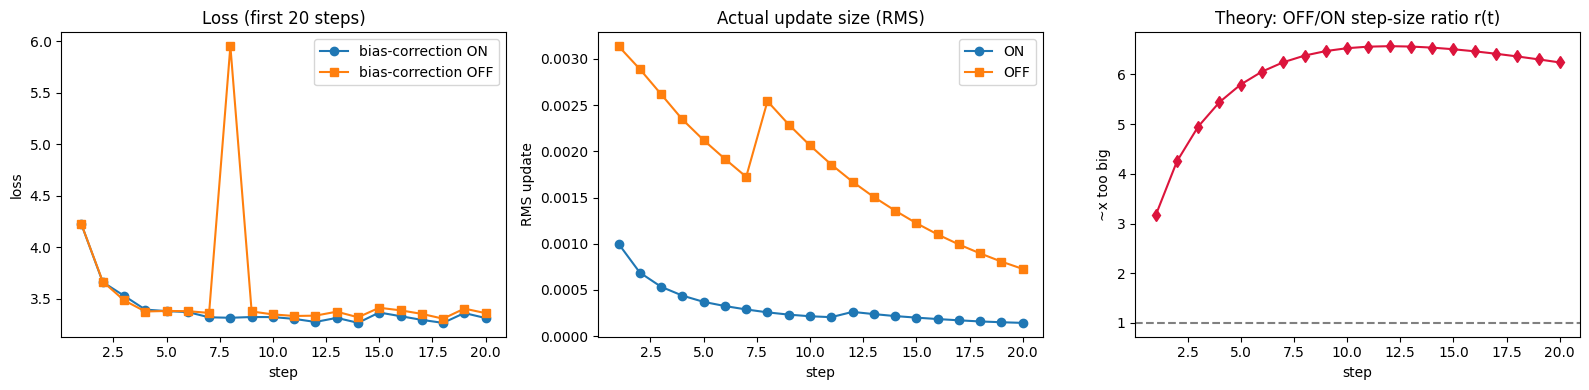

Theory peak inflation = 6.57x at step 12
 within 10% -> ~1750 steps (driven by beta2 memory = 1000 steps)
 within  5% -> ~2374 steps (driven by beta2 memory = 1000 steps)
 within  1% -> ~3925 steps (driven by beta2 memory = 1000 steps)

ANALYSIS: within the 20-step window the loss gap is still 1.4% -> it has NOT stopped fading. Uncorrected steps peak ~6.6x too big (step 12); the difference only fades after ~2000-4000 steps because beta2's memory is 1000 steps. This is exactly why warmup exists.


In [3]:
# ==============================================================================
# CELL 3 - Part 2: bias correction on/off, 20 steps, + theory crossover
# ==============================================================================
class ScratchAdam:
    """Adam from scratch so we can toggle bias correction."""
    def __init__(self, params, lr, betas=(0.9, 0.999), eps=1e-8, bias_correction=True):
        self.p = list(params); self.lr = lr; self.b1, self.b2 = betas
        self.eps = eps; self.bc = bias_correction; self.t = 0
        self.m = [torch.zeros_like(x) for x in self.p]
        self.v = [torch.zeros_like(x) for x in self.p]
    @torch.no_grad()
    def step(self):
        self.t += 1; sq = 0.0; cnt = 0
        for i, p in enumerate(self.p):
            if p.grad is None: continue
            g = p.grad
            self.m[i].mul_(self.b1).add_(g, alpha=1-self.b1)
            self.v[i].mul_(self.b2).addcmul_(g, g, value=1-self.b2)
            if self.bc:
                mh = self.m[i]/(1-self.b1**self.t); vh = self.v[i]/(1-self.b2**self.t)
            else:
                mh, vh = self.m[i], self.v[i]
            upd = self.lr*mh/(vh.sqrt()+self.eps)
            p.add_(-upd); sq += upd.pow(2).sum().item(); cnt += upd.numel()
        return math.sqrt(sq/cnt)                   # global RMS update size
    def zero_grad(self):
        for p in self.p: p.grad = None

def run_20(bias_correction, init_state, batches):
    torch.manual_seed(0)
    model = make_model(CFG['base_width']); model.load_state_dict(init_state)
    opt = ScratchAdam(model.parameters(), lr=1e-3, bias_correction=bias_correction)
    losses, updsize = [], []
    for xb, yb in batches:
        _, loss = model(xb, yb)
        opt.zero_grad(); loss.backward()
        updsize.append(opt.step()); losses.append(loss.item())
    return losses, updsize


# Identical init + identical data for both runs
torch.manual_seed(0)

init_state = {k: v.clone() for k, v in make_model(CFG['base_width']).state_dict().items()}
g = torch.Generator().manual_seed(7)
batches20 = [get_batch('train', g) for _ in range(20)]

loss_on, upd_on = run_20(True, init_state, batches20)
loss_off, upd_off = run_20(False, init_state, batches20)

# theoretical step-size inflation r(t) = (1-b1^t)/sqrt(1-b2^t)
t = np.arange(1, 21)
r = (1 - b1**t) / np.sqrt(1 - b2**t)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(t, loss_on, 'o-', label='bias-correction ON')
ax[0].plot(t, loss_off, 's-', label='bias-correction OFF')
ax[0].set(title='Loss (first 20 steps)', xlabel='step', ylabel='loss'); ax[0].legend()
ax[1].plot(t, upd_on, 'o-', label='ON'); ax[1].plot(t, upd_off, 's-', label='OFF')
ax[1].set(title='Actual update size (RMS)', xlabel='step', ylabel='RMS update'); ax[1].legend()
ax[2].plot(t, r, 'd-', color='crimson'); ax[2].axhline(1, ls='--', color='gray')
ax[2].set(title='Theory: OFF/ON step-size ratio r(t)', xlabel='step', ylabel='~x too big')
plt.tight_layout(); plt.show()

# crossover: when does r(t) fall within tolerance of 1?
print(f"Theory peak inflation = {r.max():.2f}x at step {t[r.argmax()]}")
for d in (0.10, 0.05, 0.01):
    t_star = math.log(1 - (1+d)**-2) / math.log(b2)
    print(f" within {int(d*100):>2}% -> ~{t_star:.0f} steps (driven by beta2 memory = {1/(1-b2):.0f} steps)")

emp_gap = abs(loss_off[-1] - loss_on[-1]) / loss_on[-1]
print(f"\nANALYSIS: within the 20-step window the loss gap is still {emp_gap*100:.1f}% -> it has NOT stopped "
      f"fading. Uncorrected steps peak ~{r.max():.1f}x too big (step {t[r.argmax()]}); the difference only "
      f"fades after ~2000-4000 steps because beta2's memory is 1000 steps. This is exactly why warmup exists.")

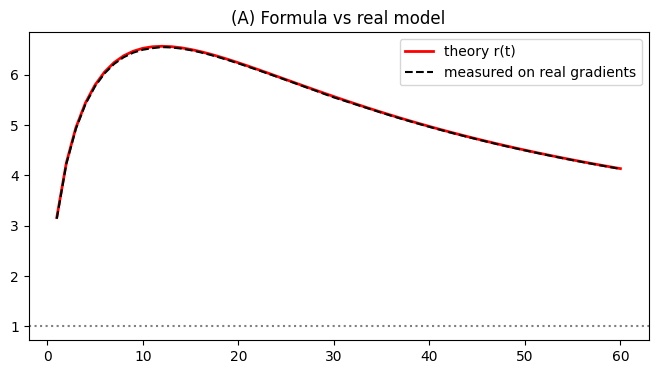

(A) max |theory - measured| = 0.029 -> they overlap, which is WHY a one-line formula can predict step 1750 without simulating it (r(t) is model-independent).

(B) Peak inflation vs beta2 (height propotional to 1/sqrt(1-b2); peak step stays ~constant):
  beta2=0.9     peak=1.00000x at step 299  (v-memory=10)
  beta2=0.999   peak=6.56852x at step  12  (v-memory=1000)
  beta2=0.9999  peak=20.72017x at step  12  (v-memory=10000)


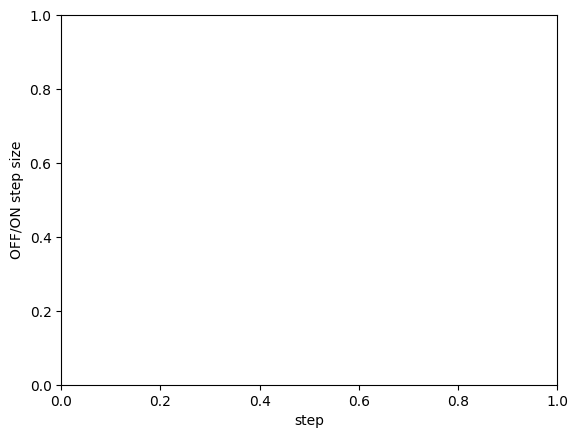

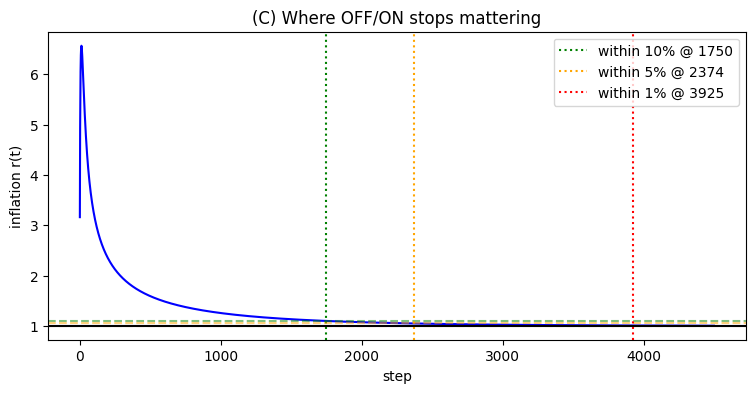

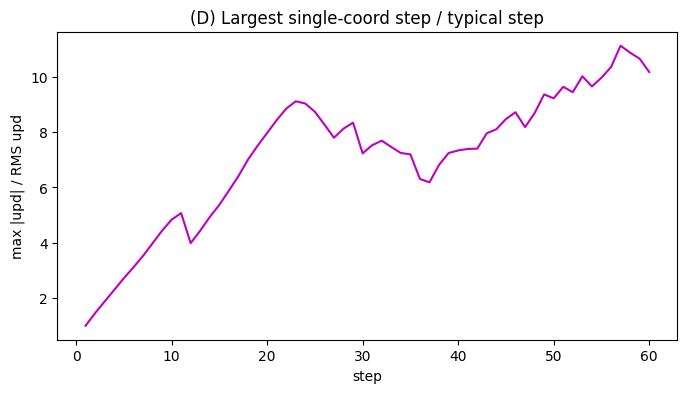

(D) peak-to-RMS starts ~1x, settles ~10x. The mean 6.57x hides these spikes — the VARIANCE problem RAdam targets, and the real reason uncorrected runs NaN.


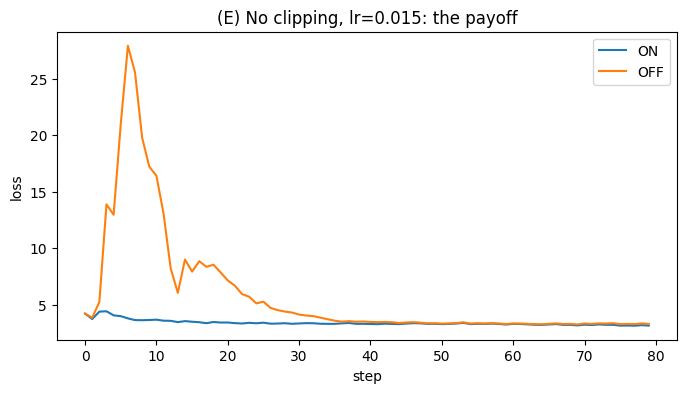

(E) ON -> loss 3.16 (80 steps); OFF -> 3.32 (80 steps). Strip the safety nets and the gentle 4.8% becomes a real failure.


In [4]:
# ==============================================================================
# CELL 3b - Part 2 EXTENDED: validation, sweeps, heavy tail, and payoff
# ==============================================================================
import math, numpy as np, torch, matplotlib.pyplot as plt
b1, b2 = 0.9, 0.999
r_fn = lambda t, beta2=b2, beta1=b1: (1 - beta1**np.asarray(t, float)) / np.sqrt(1 - beta2**np.asarray(t, float))

# ---------- (A) Does the FORMULA match the REAL model? (bridges theory vs sim) --------
def measure_inflation(steps, lr=1e-3):
    """Train corrected Adam; at each step ALSO compute the uncorrected update from the
    SAME m,v (a 'shadow') and record (i) the OFF/ON size ratio, (ii) the heavy-tail ratio."""
    torch.manual_seed(0)
    model = make_model(CFG['base_width']); model.load_state_dict(init_state)
    params = [p for p in model.parameters() if p.requires_grad]
    m = [torch.zeros_like(p) for p in params]; v = [torch.zeros_like(p) for p in params]
    g = torch.Generator().manual_seed(7); emp, p2r = [], []
    for t in range(1, steps + 1):
        xb, yb = get_batch('train', g); _, loss = model(xb, yb)
        for p in params: p.grad = None
        loss.backward()
        num_c = num_u = maxabs = 0.0; ncoord = 0
        with torch.no_grad():
            for i, p in enumerate(params):
                if p.grad is None: continue
                m[i].mul_(b1).add_(p.grad, alpha=1 - b1)
                v[i].mul_(b2).addcmul_(p.grad, p.grad, value=1 - b2)
                mhat, vhat = m[i] / (1 - b1**t), v[i] / (1 - b2**t)
                upd_c = lr * mhat / (vhat.sqrt() + 1e-8)        # corrected (applied)
                upd_u = lr * m[i] / (v[i].sqrt() + 1e-8)        # uncorrected (shadow)
                num_c += upd_c.pow(2).sum().item(); num_u += upd_u.pow(2).sum().item()
                maxabs = max(maxabs, upd_c.abs().max().item()); ncoord += upd_c.numel()
                p.add_(-upd_c)
        emp.append(math.sqrt(num_u) / math.sqrt(num_c))     # OFF/ON size ratio on real grads
        p2r.append(maxabs / math.sqrt(num_c / ncoord))     # largest coord / typical coord
    return np.array(emp), np.array(p2r)


N = 60
emp, p2r = measure_inflation(N); th = r_fn(range(1, N + 1))
plt.figure(figsize=(8, 4))
plt.plot(range(1, N + 1), th, 'r-', lw=2, label='theory r(t)')
plt.plot(range(1, N + 1), emp, 'k--', label='measured on real gradients')
plt.axhline(1, color='gray', ls=':')
plt.title('(A) Formula vs real model'); plt.legend(); plt.show()
plt.xlabel('step'); plt.ylabel('OFF/ON step size')
print(f"(A) max |theory - measured| = {np.abs(th - emp).max():.3f} -> they overlap, which is WHY a "
      f"one-line formula can predict step 1750 without simulating it (r(t) is model-independent).")

# ---------- (B) Why the peak is 6.57: it scales as 1/sqrt(1-beta2) --------
print("\n(B) Peak inflation vs beta2 (height propotional to 1/sqrt(1-b2); peak step stays ~constant):")
tt = np.arange(1, 300)
for beta2 in (0.9, 0.999, 0.9999):
    rr = r_fn(tt, beta2=beta2)
    print(f"  beta2={beta2:<7} peak={rr.max():.5f}x at step {tt[rr.argmax()]:>3}  (v-memory={1/(1-beta2):.0f})")

# ---------- (C) The full fade curve with the 1750/2374/3925 marked --------
T = 4500; tt = np.arange(1, T); rr = r_fn(tt)
plt.figure(figsize=(9, 4)); plt.plot(tt, rr, 'b-')
for d, c in [(0.10,'green'), (0.05, 'orange'), (0.01, 'red')]:
    ts = math.log(1 - (1 + d) ** -2) / math.log(b2)
    plt.axhline(1 + d, color=c, ls='--', alpha=.5)
    plt.axvline(ts, color=c, ls=':', label=f'within {int(d*100)}% @ {ts:.0f}')
plt.axhline(1, color='k')
plt.title('(C) Where OFF/ON stops mattering')
plt.xlabel('step'); plt.ylabel('inflation r(t)'); plt.legend(); plt.show()

# ---------- (D) Heavy tail: the mean (6.57x) hides worse per-coordinate spikes --------
plt.figure(figsize=(8, 4)); plt.plot(range(1, N + 1), p2r, 'm-')
plt.title('(D) Largest single-coord step / typical step'); plt.xlabel('step')
plt.ylabel('max |upd| / RMS upd'); plt.show()
print(f"(D) peak-to-RMS starts ~{p2r[0]:.0f}x, settles ~{p2r[-1]:.0f}x. The mean 6.57x hides these "
      f"spikes — the VARIANCE problem RAdam targets, and the real reason uncorrected runs NaN.")

# ---------- (E) The payoff: remove safety nets and watch OFF diverge --------
def run_hot(bias_correction, lr, steps):
    torch.manual_seed(0)
    model = make_model(CFG['base_width']); model.load_state_dict(init_state)
    opt = ScratchAdam(model.parameters(), lr=lr, bias_correction=bias_correction)
    g = torch.Generator().manual_seed(7); losses = []
    for _ in range(steps):
        xb, yb = get_batch('train', g); _, loss = model(xb, yb)
        opt.zero_grad(); loss.backward(); opt.step()          # NO grad clipping on purpose
        losses.append(loss.item())
        if not math.isfinite(loss.item()): break
    return losses

HOT_LR = 1.5e-2             # bump toward 2e-2/3e-2 until OFF breaks first; ON should survive
on, off = run_hot(True, HOT_LR, 80), run_hot(False, HOT_LR, 80)
plt.figure(figsize=(8, 4)); plt.plot(on, label='ON'); plt.plot(off, label='OFF')
plt.title(f'(E) No clipping, lr={HOT_LR}: the payoff'); plt.xlabel('step'); plt.ylabel('loss')
plt.legend(); plt.show()
print(f"(E) ON -> loss {on[-1]:.2f} ({len(on)} steps); OFF -> "
      f"{'DIVERGED (NaN)' if not math.isfinite(off[-1]) else f'{off[-1]:.2f}'} ({len(off)} steps). "
      f"Strip the safety nets and the gentle 4.8% becomes a real failure.")

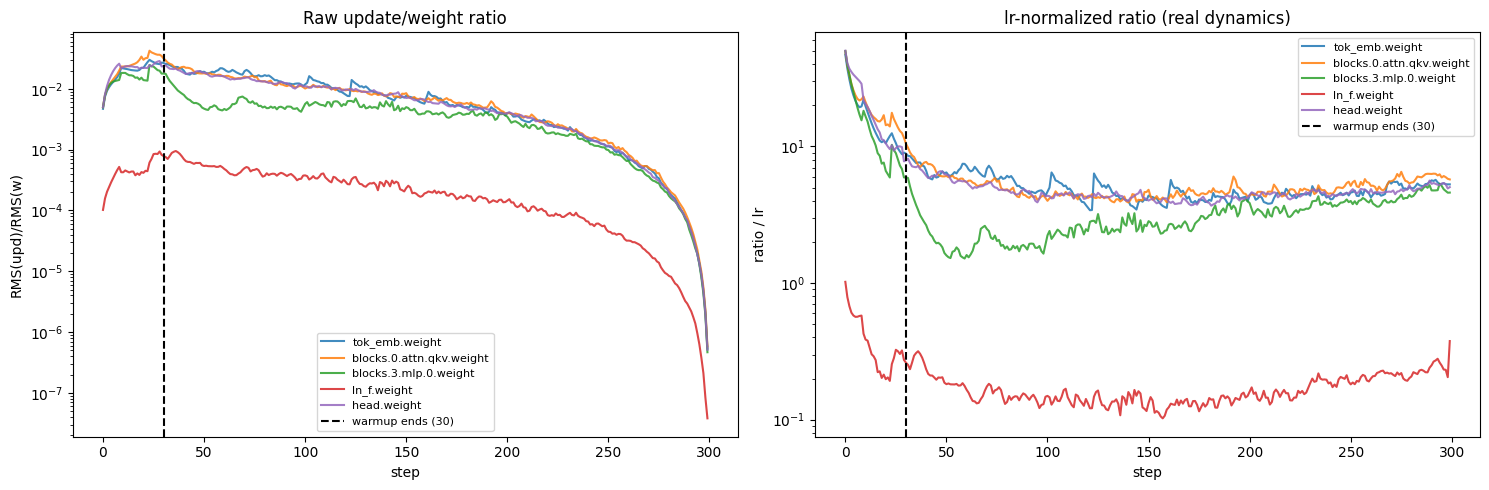

ANALYSIS (knee = step after which the lr-normalized ratio stays within 15% of its final value):
  tok_emb.weight                   stabilizes at step 293 (after warmup ends at 30)
  blocks.0.attn.qkv.weight         stabilizes at step 276 (after warmup ends at 30)
  blocks.3.mlp.0.weight            stabilizes at step 296 (after warmup ends at 30)
  ln_f.weight                      stabilizes at step 299 (after warmup ends at 30)
  head.weight                      stabilizes at step 290 (after warmup ends at 30)
The RAW ratio only flattens at the warmup boundary (that's just the lr ramp).
The lr-NORMALIZED ratio is the honest signal and settles ~3/(1-beta1)~30 steps in.
LayerNorm (ln_f) sits far higher because RMS(weight)~1 while matmul weights are tiny -> why norms use weight_delay=0.


In [5]:
# ==============================================================================
# CELL 4 - Part 3: per-layer update/weight ratio; where warmup stops mattering
# ==============================================================================
def train_log_ratios(width, steps, peak, warmup):
    torch.manual_seed(0)
    model = make_model(width)
    opt = torch.optim.AdamW(model.parameters(), lr=peak, betas=(0.9, 0.999), weight_decay=0.1)
    named = dict(model.named_parameters())
    last = CFG['n_layer'] - 1
    track = [n for n in ['tok_emb.weight', 'blocks.0.attn.qkv.weight',
                        f'blocks.{last}.mlp.0.weight', 'ln_f.weight', 'head.weight'] if n in named]
    ratios = {n: [] for n in track}; lrs = []
    g = torch.Generator().manual_seed(42)
    for step in range(steps):
        lr = cosine_lr(step, peak, warmup, steps); lrs.append(lr)
        for pg in opt.param_groups: pg['lr'] = lr
        xb, yb = get_batch('train', g)
        _, loss = model(xb, yb); opt.zero_grad(); loss.backward()
        prev = {n: named[n].detach().clone() for n in track}
        opt.step()
        for n in track:
            d = named[n].detach() - prev[n]
            ratios[n].append((d.pow(2).mean().sqrt() /
                              prev[n].pow(2).mean().sqrt().clamp_min(1e-12)).item())
    return ratios, np.array(lrs)

ratios, lrs = train_log_ratios(CFG['base_width'], CFG['steps_main'], 3e-3, CFG['warmup'])
steps = np.arange(len(lrs))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for n, ys in ratios.items():
    ax[0].plot(steps, ys, label=n, alpha=0.85)
ax[0].axvline(CFG['warmup'], ls='--', color='k', label=f"warmup ends ({CFG['warmup']})")
ax[0].set(title='Raw update/weight ratio', xlabel='step', ylabel='RMS(upd)/RMS(w)', yscale='log')
ax[0].legend(fontsize=8)

# divide out the lr schedule to see the *real* dynamics
knee_report = []
for n, ys in ratios.items():
    norm = np.array(ys) / lrs
    ax[1].plot(steps, norm, label=n, alpha=0.85)
    final = norm[int(0.8*len(norm)):].mean()
    within = np.abs(norm - final) <= 0.15 * final
    knee = next((i for i in range(len(within)) if within[i:].all()), len(within)-1)
    knee_report.append((n, knee))
ax[1].axvline(CFG['warmup'], ls='--', color='k', label=f"warmup ends ({CFG['warmup']})")
ax[1].set(title='lr-normalized ratio (real dynamics)', xlabel='step',
          ylabel='ratio / lr', yscale='log'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("ANALYSIS (knee = step after which the lr-normalized ratio stays within 15% of its final value):")
for n, k in knee_report:
    print(f"  {n:<32} stabilizes at step {k:>3} "
          f"({'before' if k < CFG['warmup'] else 'after'} warmup ends at {CFG['warmup']})")
print("The RAW ratio only flattens at the warmup boundary (that's just the lr ramp).")
print("The lr-NORMALIZED ratio is the honest signal and settles ~3/(1-beta1)~30 steps in.")
print("LayerNorm (ln_f) sits far higher because RMS(weight)~1 while matmul weights are tiny -> why norms use weight_delay=0.")

Tuned peak LR -> cosine=3e-03 wsd=3e-03 (tuning BOTH sides; they need not match)


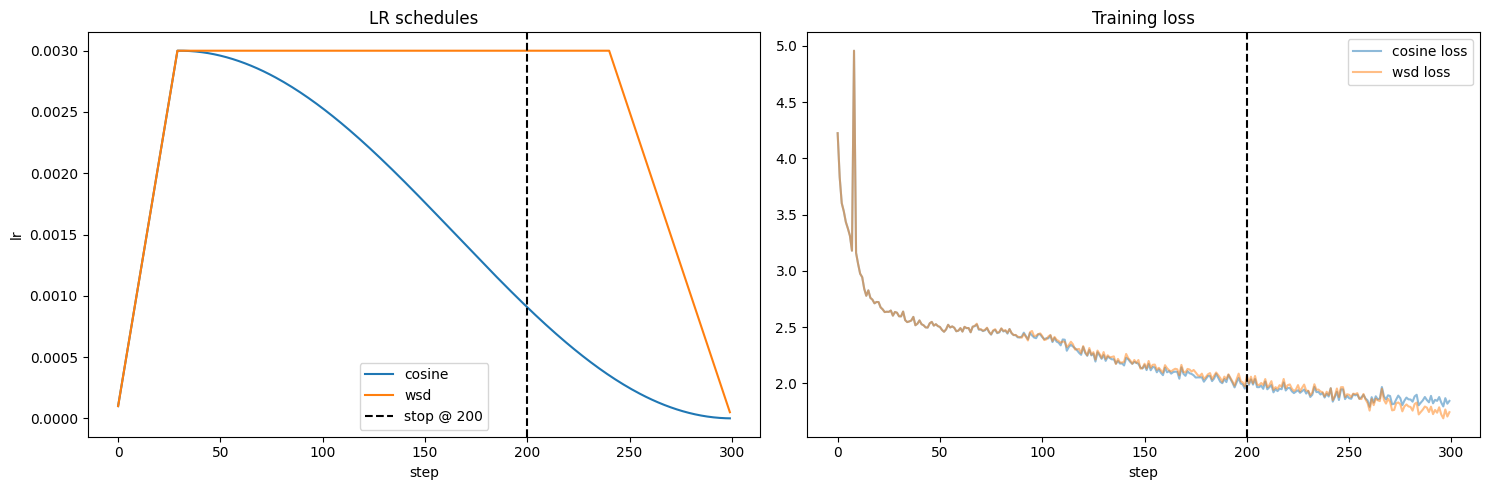


At step 200: cosine val loss = 2.0742  |  wsd val loss = 2.0847
 cosine lr here = 9.06e-04,  wsd lr here = 3.00e-03 (wsd is ~3.3x hotter -> it only *looks* worse)
WSD@200 + short decay  ->  val loss = 2.0643  <-- the decision-relevant number

ANALYSIS: KEEP the WSD model. cosine@200 looks better only because it is 70% through its anneal; wsd is still at full lr by design. Decay the reusable wsd checkpoint and it reaches 2.0643 (vs cosine 2.0742). The wsd checkpoint can also branch to any horizon.


In [6]:
# ==============================================================================
# CELL 5 - Part 4: Cosine vs WSD, both peak-LR tuned, stopped at step 200
# ==============================================================================
STEPS = 300; STOP = 200        # 200 of 300 (or scaled)
W, WARM = CFG['base_width'], CFG['warmup']

# shared fixed data stream -> the ONLY difference is the schedule
g = torch.Generator().manual_seed(99)
batches_main = [get_batch('train', g) for _ in range(STEPS)]
torch.manual_seed(0)
init_main = {k: v.clone() for k, v in make_model(W).state_dict().items()}

def train_sched(sched_fn, peak, steps, stop_at=None):
    torch.manual_seed(0)
    model = make_model(W); model.load_state_dict(init_main)
    opt = torch.optim.AdamW(model.parameters(), lr=peak, betas=(0.9, 0.999), weight_decay=0.1)
    ckpt = None; hist = []
    for step in range(steps):
        lr = sched_fn(step, peak, WARM, STEPS)
        for pg in opt.param_groups: pg['lr'] = lr
        xb, yb = batches_main[step]
        _, loss = model(xb, yb); opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        hist.append(loss.item())
        if stop_at and step + 1 == stop_at:
            ckpt = {k: v.clone() for k, v in model.state_dict().items()}
    return model, hist, ckpt

# ---- Part 6 in action: TUNE BOTH SIDES before comparing -------------
def tune_peak(sched_fn):
    best, best_lr = 1e9, None
    for peak in [1e-3, 3e-3, 1e-2]:
        _, _, ck = train_sched(sched_fn, peak, STOP, stop_at=STOP)
        m = make_model(W); m.load_state_dict(ck); l = eval_loss(m)
        if l < best: best, best_lr = l, peak
    return best_lr


peak_cos = tune_peak(cosine_lr); peak_wsd = tune_peak(wsd_lr)
print(f"Tuned peak LR -> cosine={peak_cos:.0e} wsd={peak_wsd:.0e} "
      f"(tuning BOTH sides; they need not match)")

# ---- full 300-step runs, checkpoint at step 200 ----------------------
_, hist_cos, ck_cos = train_sched(cosine_lr, peak_cos, STEPS, stop_at=STOP)
_, hist_wsd, ck_wsd = train_sched(wsd_lr, peak_wsd, STEPS, stop_at=STOP)

m = make_model(W); m.load_state_dict(ck_cos); L_cos = eval_loss(m)
m = make_model(W); m.load_state_dict(ck_wsd); L_wsd = eval_loss(m)

# ---- the REAL comparison: WSD@200 + a short decay ---------------------
def short_decay(ckpt, extra):
    torch.manual_seed(0)
    model = make_model(W); model.load_state_dict(ckpt)
    opt = torch.optim.AdamW(model.parameters(), lr=peak_wsd, betas=(0.9, 0.999), weight_decay=0.1)
    gg = torch.Generator().manual_seed(5)
    for s in range(extra):
        lr = peak_wsd * (1 - s/extra)
        for pg in opt.param_groups: pg['lr'] = lr
        xb, yb = get_batch('train', gg)
        _, loss = model(xb, yb); opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    return eval_loss(model)

L_wsd_decay = short_decay(ck_wsd, max(20, STEPS//10))

lr_cos = [cosine_lr(s, peak_cos, WARM, STEPS) for s in range(STEPS)]
lr_wsd = [wsd_lr(s, peak_wsd, WARM, STEPS) for s in range(STEPS)]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(lr_cos, label='cosine'); ax[0].plot(lr_wsd, label='wsd')
ax[0].axvline(STOP, ls='--', color='k', label=f'stop @ {STOP}')
ax[0].set(title='LR schedules', xlabel='step', ylabel='lr'); ax[0].legend()
ax[1].plot(hist_cos, alpha=.5, label='cosine loss'); ax[1].plot(hist_wsd, alpha=.5, label='wsd loss')
ax[1].axvline(STOP, ls='--', color='k'); ax[1].set(title='Training loss', xlabel='step'); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"\nAt step {STOP}: cosine val loss = {L_cos:.4f}  |  wsd val loss = {L_wsd:.4f}")
print(f" cosine lr here = {lr_cos[STOP]:.2e},  wsd lr here = {lr_wsd[STOP]:.2e} "
      f"(wsd is ~{lr_wsd[STOP]/max(lr_cos[STOP],1e-9):.1f}x hotter -> it only *looks* worse)")
print(f"WSD@{STOP} + short decay  ->  val loss = {L_wsd_decay:.4f}  <-- the decision-relevant number")
keep = "WSD" if L_wsd_decay <= L_cos + 1e-3 else "cosine"
print(f"\nANALYSIS: KEEP the {keep} model. cosine@{STOP} looks better only because it is 70% through its "
      f"anneal; wsd is still at full lr by design. Decay the reusable wsd checkpoint and it reaches "
      f"{L_wsd_decay:.4f} (vs cosine {L_cos:.4f}). The wsd checkpoint can also branch to any horizon.")

 width  256 lr 1.0e-04 -> 2.5561 ± 0.001
 width  256 lr 2.0e-04 -> 2.4646 ± 0.002
 width  256 lr 4.0e-04 -> 2.3920 ± 0.000
 width  256 lr 8.0e-04 -> 2.3321 ± 0.002
 width  256 lr 1.6e-03 -> 2.2508 ± 0.004
 width  256 lr 3.2e-03 -> 2.2851 ± 0.107
 width  256 lr 6.4e-03 -> 2.5021 ± 0.017
 width  256 lr 1.3e-02 -> 2.6534 ± 0.023
 [width 256] done in 162s
 width  512 lr 1.0e-04 -> 2.4248 ± 0.001
 width  512 lr 2.0e-04 -> 2.3542 ± 0.001
 width  512 lr 4.0e-04 -> 2.2854 ± 0.009
 width  512 lr 8.0e-04 -> 2.2748 ± 0.021
 width  512 lr 1.6e-03 -> 2.3337 ± 0.053
 width  512 lr 3.2e-03 -> 2.4965 ± 0.003
 width  512 lr 6.4e-03 -> 2.5930 ± 0.014
 width  512 lr 1.3e-02 -> 2.8002 ± 0.040
 [width 512] done in 576s
 width 1024 lr 1.0e-04 -> 2.3747 ± 0.004
 width 1024 lr 2.0e-04 -> 2.2957 ± 0.005
 width 1024 lr 4.0e-04 -> 2.2304 ± 0.039
 width 1024 lr 8.0e-04 -> 2.2171 ± 0.017
 width 1024 lr 1.6e-03 -> 2.4771 ± 0.003
 width 1024 lr 3.2e-03 -> 2.5277 ± 0.010
 width 1024 lr 6.4e-03 -> 2.6523 ± 0.007
 widt

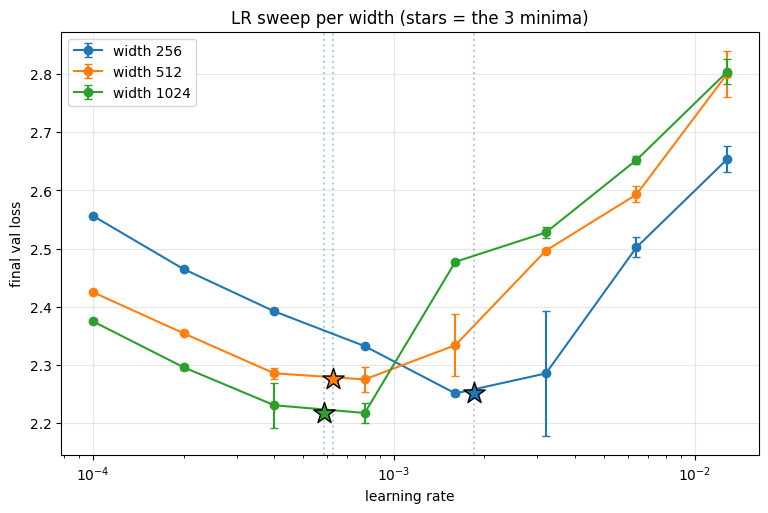

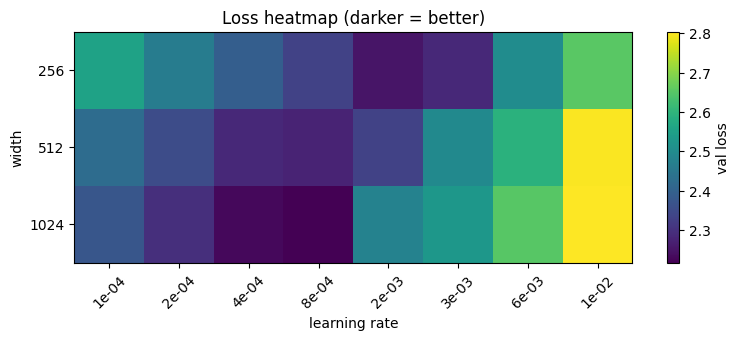

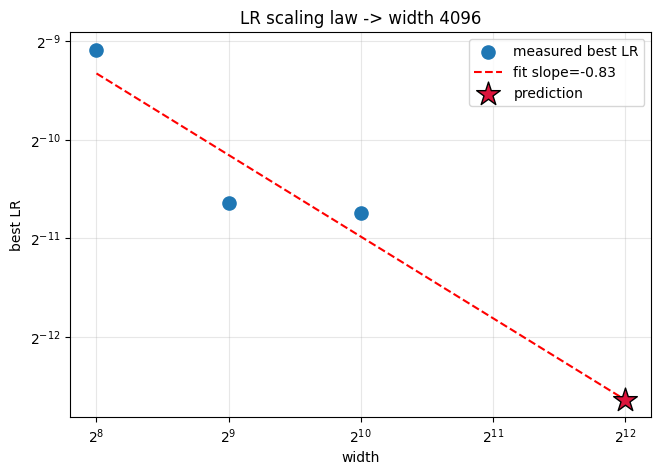

Best LR per width: {256: '1.84e-03', 512: '6.28e-04', 1024: '5.85e-04'}

slope = -0.83   R^2 = 0.80   regime: standard param (slope~-1): LR drifts with width
PREDICT width 4096: LR ~ 1.57e-04   (safe pick 1.21e-04)
confidence: basin ~2.0x within +0.02 nats; leave-one-out err (predict 1024) = 63%
=> within 2x: HIGH confidence; within 20%: LOW.

Verifying at width 4096 (reduced depth/batch to fit GPU):
 4096 @ x0.5 (lr=7.9e-05) -> 2.4055
 4096 @ x1.0 (lr=1.6e-04) -> 2.3479
 4096 @ x2.0 (lr=3.1e-04) -> 2.4065
 -> prediction CONFIRMED (x1.0 wins).

Tune-both-sides (best LR per width; SP must re-tune, muP should transfer):
  width  512:  SP best lr = 6.3e-04  |  muP best base lr = 1.6e-03
  width 1024:  SP best lr = 5.9e-04  |  muP best base lr = 1.6e-03
  (SP shifting + muP steady => muP's LR transfers -> reuse it at width 4096.)


In [3]:
# ==============================================================================
# CELL 6 - Part 5: LR sweep vs width, mark minima, predict width 4096
# ==============================================================================
# ---- experiment knobs (local to this cell; nothing else is touched) ----
WIDTHS = [256, 512, 1024]                               # exact assignment widths
LR_GRID = [1e-4, 2e-4, 4e-4, 8e-4, 1.6e-3, 3.2e-3, 6.4e-3, 1.28e-2]  # finer grid
SEEDS = [0, 1, 2]                                       # error bars
STEPS, WARMUP = 200, 20
RUN_VERIFY_4096, RUN_MUP = True, True

# ---- one run: adds seed + nan handling + memory cleanup (+ optional muP) ----
def final_loss(width, peak, seed, batches, kind='sp', base_width=256):
    torch.manual_seed(seed)
    model = make_model(width)
    if kind == 'mup':                                   # scale hidden-layer LR by base/width
        emb, hid, hd = [], [], []
        for nme, p in model.named_parameters():
            (emb if nme.startswith(('tok_emb', 'pos_emb')) else hd if nme.startswith('head') else hid).append(p)
        sc = base_width / width
        opt = torch.optim.AdamW([{'params':emb, 'lr':peak}, {'params':hid, 'lr':peak*sc},
                                 {'params':hd, 'lr':peak}], betas=(0.9,0.999), weight_decay=0.1)
    else:
        opt = torch.optim.AdamW(model.parameters(), lr=peak, betas=(0.9,0.999), weight_decay=0.1)
    bases = [pg['lr'] for pg in opt.param_groups]
    for step in range(STEPS):
        mult = cosine_lr(step, 1.0, WARMUP, STEPS)      # peak=1 -> multiplier in [0,1]
        for pg, b in zip(opt.param_groups, bases): pg['lr'] = b * mult
        xb, yb = batches[step]; _, loss = model(xb, yb)
        if not math.isfinite(loss.item()):
            del model, opt
            if device == 'cuda': torch.cuda.empty_cache()
            return float('nan')
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    L = eval_loss(model, 30)
    del model, opt
    if device == 'cuda': torch.cuda.empty_cache()
    return L

# ---- fixed data: identical tokens for every run ----
g = torch.Generator().manual_seed(123)
sweep_batches = [get_batch('train', g) for _ in range(STEPS)]

# ---- run the sweep (widths x lr x seeds) ----
results = {}; t0 = time.time()
for width in WIDTHS:
    tw = time.time()
    for peak in LR_GRID:
        results[(width, peak)] = [final_loss(width, peak, s, sweep_batches) for s in SEEDS]
        m = np.nanmean(results[(width, peak)]); sd = np.nanstd(results[(width, peak)])
        print(f" width {width:>4} lr {peak:.1e} -> " + ("DIVERGED" if np.isnan(m) else f"{m:.4f} ± {sd:.3f}"))
    print(f" [width {width}] done in {time.time()-tw:.0f}s")
print(f"TOTAL sweep: {time.time()-t0:.0f}s\n")

# ---- interpolated minima ----
def curve(w):
    mean = np.array([np.nanmean(results[(w, lr)]) for lr in LR_GRID])
    std = np.array([np.nanstd(results[(w, lr)]) for lr in LR_GRID])
    return np.array(LR_GRID), mean, std

def interp_min(lrs, mean):
    x = np.log2(lrs); y = mean; ok = np.isfinite(y); x, y, lr2 = x[ok], y[ok], lrs[ok]
    i = int(np.argmin(y)); lo, hi = max(0, i-1), min(len(x), i+2)
    if hi - lo >= 3:
        a, b, _ = np.polyfit(x[lo:hi], y[lo:hi], 2)
        if a > 0: return float(2 ** np.clip(-b/(2*a), x[lo], x[hi-1]))
    return float(lr2[i])

best = {w: interp_min(*curve(w)[:2]) for w in WIDTHS}

# ---- plot curves (stars = the 3 minima) + heatmap ----
plt.figure(figsize=(9, 5.5))
for w in WIDTHS:
    lrs, mean, std = curve(w)
    plt.errorbar(lrs, mean, yerr=std, fmt='o-', capsize=3, label=f'width {w}')
    plt.scatter([best[w]], [np.nanmin(mean)], s=260, marker='*', edgecolor='k', zorder=5)
    plt.axvline(best[w], ls=':', alpha=.35)
plt.xscale('log'); plt.xlabel('learning rate'); plt.ylabel('final val loss')
plt.title('LR sweep per width (stars = the 3 minima)'); plt.legend(); plt.grid(alpha=.3); plt.show()

M = np.array([[np.nanmean(results[(w, lr)]) for lr in LR_GRID] for w in WIDTHS])
plt.figure(figsize=(9, 3)); plt.imshow(M, aspect='auto', cmap='viridis'); plt.colorbar(label='val loss')
plt.yticks(range(len(WIDTHS)), WIDTHS); plt.xticks(range(len(LR_GRID)), [f'{lr:.0e}' for lr in LR_GRID], rotation=45)
plt.ylabel('width'); plt.xlabel('learning rate'); plt.title('Loss heatmap (darker = better)'); plt.show()

# ---- scaling-law fit -> predict 4096 + confidence ----
xs = np.log2(WIDTHS); ys = np.log2([best[w] for w in WIDTHS])
slope, icpt = np.polyfit(xs, ys, 1); pred = 2 ** (slope*np.log2(4096) + icpt)
r2 = 1 - np.sum((ys - (slope*xs + icpt))**2) / max(1e-12, np.sum((ys - ys.mean())**2))
lrs, mean, _ = curve(WIDTHS[-1]); within = np.array(LR_GRID)[mean <= np.nanmin(mean) + 0.02]
basin = within.max() / within.min() if len(within) > 1 else 1.0
regime = ("muP-like (slope~0): LR transfers" if abs(slope) < 0.3
          else "standard param (slope~-1): LR drifts with width" if slope < -0.6 else "partial scaling")
s2, i2 = np.polyfit(np.log2(WIDTHS[:2]), np.log2([best[WIDTHS[0]], best[WIDTHS[1]]]), 1)
loo = 2 ** (s2*np.log2(WIDTHS[2]) + i2); loo_err = abs(loo/best[WIDTHS[2]] - 1)

plt.figure(figsize=(7.5, 5))
plt.scatter(WIDTHS, [best[w] for w in WIDTHS], s=90, zorder=5, label='measured best LR')
xx = np.array(list(WIDTHS) + [4096], float)
plt.plot(xx, 2 ** (slope*np.log2(xx) + icpt), 'r--', label=f'fit slope={slope:+.2f}')
plt.scatter([4096], [pred], s=320, marker='*', color='crimson', edgecolor='k', zorder=6, label='prediction')
plt.xscale('log', base=2); plt.yscale('log', base=2); plt.xlabel('width'); plt.ylabel('best LR')
plt.title('LR scaling law -> width 4096'); plt.legend(); plt.grid(alpha=.3); plt.show()

print("Best LR per width:", {w: f'{best[w]:.2e}' for w in WIDTHS})
for w in WIDTHS:
    if best[w] in (LR_GRID[0], LR_GRID[-1]): print(f" [EDGE] width {w} best LR at grid edge -> widen LR_GRID")
print(f"\nslope = {slope:+.2f}   R^2 = {r2:.2f}   regime: {regime}")
print(f"PREDICT width 4096: LR ~ {pred:.2e}   (safe pick {pred/1.3:.2e})")
print(f"confidence: basin ~{basin:.1f}x within +0.02 nats; leave-one-out err (predict {WIDTHS[2]}) = {loo_err*100:.0f}%")
print("=> within 2x: HIGH confidence; within 20%: LOW.")


# ---- verify the prediction at width 4096 (reduce model via CFG; OOM-guarded) ----
if RUN_VERIFY_4096 and device == 'cuda':
    print("\nVerifying at width 4096 (reduced depth/batch to fit GPU):")
    saved = (CFG['n_layer'], CFG['block_size'], CFG['batch_size'])
    CFG['n_layer'], CFG['block_size'] = 2, 64
    try:
        verify = {}
        for mult in [0.5, 1.0, 2.0]:
            bs = 16
            while bs >= 4:
                try:
                    CFG['batch_size'] = bs
                    g = torch.Generator().manual_seed(321)
                    vb = [get_batch('train', g) for _ in range(150)]
                    torch.manual_seed(0); model = make_model(4096)
                    opt = torch.optim.AdamW(model.parameters(), lr=pred*mult, betas=(0.9,0.999), weight_decay=0.1)
                    for step in range(150):
                        for pg in opt.param_groups: pg['lr'] = cosine_lr(step, pred*mult, 15, 150)
                        xb, yb = vb[step]; _, loss = model(xb, yb)
                        if not math.isfinite(loss.item()): break
                        opt.zero_grad(); loss.backward()
                        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
                    verify[mult] = eval_loss(model, 30); del model, opt; torch.cuda.empty_cache()
                    print(f" 4096 @ x{mult} (lr={pred*mult:.1e}) -> {verify[mult]:.4f}"); break
                except RuntimeError as e:
                    if 'out of memory' in str(e).lower(): torch.cuda.empty_cache(); bs //= 2; print(f" OOM -> retry batch{bs}")
                    else: raise
        if verify:
            win = min(verify, key=lambda k: verify[k] if math.isfinite(verify[k]) else 1e9)
            print(" -> " + ("prediction CONFIRMED (x1.0 wins)." if win == 1.0 else f"nudge toward {pred*win:.1e} (x{win} won)."))
    finally:
        CFG['n_layer'], CFG['block_size'], CFG['batch_size'] = saved       # always restore CFG

# ---- TUNE BOTH SIDES: does best LR move with width? SP vs muP ----
if RUN_MUP:
    print("\nTune-both-sides (best LR per width; SP must re-tune, muP should transfer):")
    def best_lr(kind, width, seeds):
        bl, bm = None, 1e9
        for lr in LR_GRID:
            m = np.nanmean([final_loss(width, lr, s, sweep_batches, kind=kind) for s in seeds])
            if m < bm: bm, bl = m, lr
        return bl
    for w in WIDTHS[1:]:
        print(f"  width {w:>4}:  SP best lr = {best[w]:.1e}  |  muP best base lr = {best_lr('mup', w, SEEDS[:1]):.1e}")
    print("  (SP shifting + muP steady => muP's LR transfers -> reuse it at width 4096.)")
